# Your first additive models

An additive model builds a prediction from a baseline and a contribution from each feature. Those contributions can be nonlinear.

We will fit a GAM and a neural additive model to the same simulated data, compare their predictions, and inspect the relationships they learn. A short classification example then shows why additive contributions are interpreted on the link scale.

## Additive models

For a response with a Gaussian model and an identity link, the prediction is the sum of the intercept and feature effects. More generally, the effects add on a predictor scale, and an inverse link converts that sum to the response scale.

$$\eta(x)=\beta_0+\sum_j f_j(x_j),\qquad \mu(x)=g^{-1}\{\eta(x)\}.$$

In a main-effects model, changing one feature changes its own contribution. An interaction allows the contribution to depend jointly on several features; we will begin without interactions.


## Create the data

The regression response combines a sine-shaped effect of x1, a quadratic effect of x2, a shift for one group, and random noise. Because we know how the data were generated, we can compare the learned curves with the relationships the model is trying to recover.


In [1]:
import logging
import warnings
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message="You called.*self.log.*logger=True.*")
from pathlib import Path
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = ["#2563EB", "#F97316", "#10B981", "#8B5CF6", "#EF4444"]

N_SAMPLES = 1000
MAX_EPOCHS = 100
RANDOM_STATE = 7
CHECKPOINT_ROOT = Path(tempfile.mkdtemp(prefix="nampy-notebook-"))

NEURAL_FIT_KWARGS = {
    "max_epochs": MAX_EPOCHS,
    "batch_size": 128,
    "lr": 1e-2,
    "patience": 15,
    "random_state": RANDOM_STATE,
    "checkpoint_path": CHECKPOINT_ROOT,
    "logger": False,
    "enable_progress_bar": False,
    "enable_model_summary": False,
    "num_sanity_val_steps": 0,
}

rng = np.random.default_rng(RANDOM_STATE)

n = N_SAMPLES
x1 = rng.uniform(-1.0, 1.0, n)
x2 = rng.normal(size=n)
group = pd.Categorical(rng.choice(["a", "b", "c"], size=n))

X = pd.DataFrame({"x1": x1, "x2": x2, "group": group})
main_signal = np.sin(np.pi * x1) + 0.35 * x2**2 + 0.30 * (group == "b")
y_reg = main_signal + rng.normal(0.0, 0.18, n)

logit = -0.3 + 1.8 * np.sin(np.pi * x1) - 0.7 * x2 + 0.5 * (group == "c")
p_binary = 1.0 / (1.0 + np.exp(-logit))
y_binary = rng.binomial(1, p_binary)


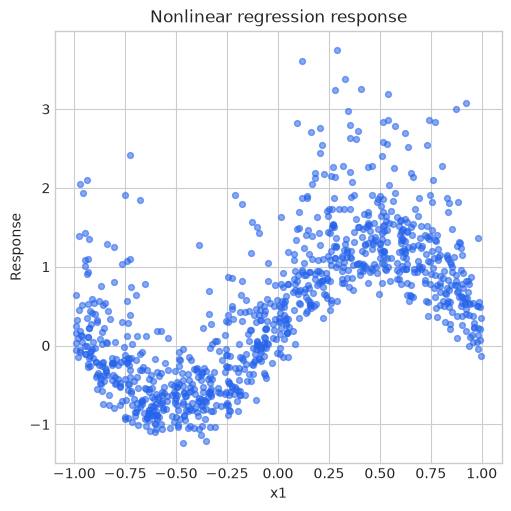

In [2]:
figure, axis = plt.subplots(figsize=(5, 5), constrained_layout=True)
axis.scatter(X["x1"], y_reg, s=18, alpha=0.55, color=COLORS[0])
axis.set(xlabel="x1", ylabel="Response", title="Nonlinear regression response")
plt.show()
plt.close("all")

The response depends on two numerical features and a group effect. This plot shows its relationship with x1; variation around the curve also reflects the other inputs and random noise.

## Fit a GAM and a NAM

The GAM represents each numerical effect with spline basis functions and penalizes excessive roughness. The NAM uses a small neural network for each feature. We fit both on the same training rows and evaluate them on the same test rows.


In [3]:
from sklearn.model_selection import train_test_split
from nampy.models import GAMRegressor, NAMRegressor

train_index, test_index = train_test_split(
    np.arange(n), test_size=0.25, random_state=RANDOM_STATE
)
X_train, X_test = X.iloc[train_index], X.iloc[test_index]
y_train, y_test = y_reg[train_index], y_reg[test_index]

gam_train = X_train.assign(y=y_train)
gam = GAMRegressor(
    formula="y ~ s(x1, bs='cr', k=9) + s(x2, bs='cr', k=9) + group",
    smoothing_method="reml",
).fit(gam_train)

nam = NAMRegressor(
    layer_sizes=[24, 12],
    dropout=0.0,
    numerical_preprocessing="minmax",
    categorical_preprocessing="one-hot",
)
nam.fit(X_train, y_train, **NEURAL_FIT_KWARGS)

comparison = pd.DataFrame(
    {
        "Model": ["GAMRegressor", "NAMRegressor"],
        "Test R2": [gam.score(X_test, y_test), nam.score(X_test, y_test)],
    }
)
comparison.style.hide(axis="index").format({"Test R2": "{:.3f}"})


Model,Test R2
GAMRegressor,0.951
NAMRegressor,0.947


Both models explain much of the variation in the test responses. Their scores are close, so prediction accuracy alone gives little reason to prefer one here. The effect plots will show whether they reached similar predictions by learning similar relationships.


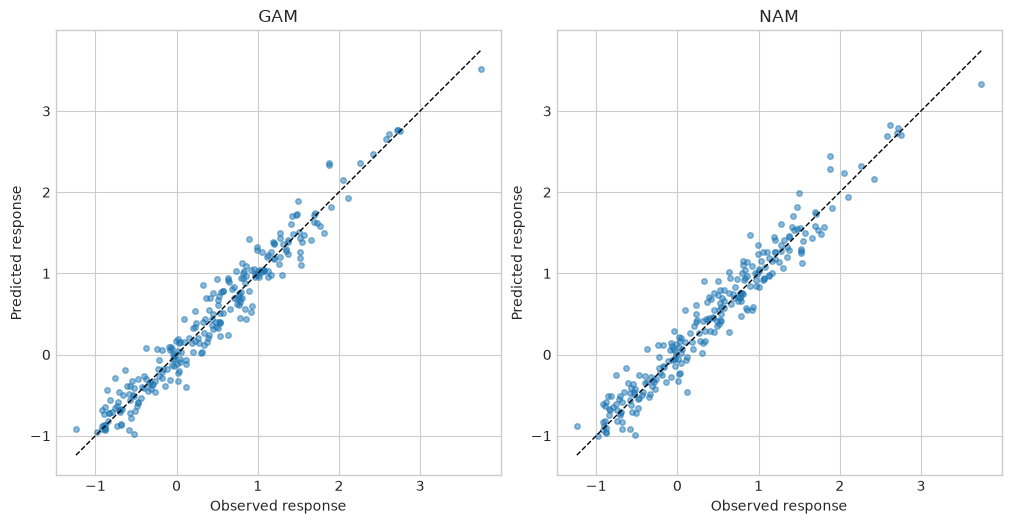

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
limits = [float(y_test.min()), float(y_test.max())]
for axis, (name, fitted) in zip(axes, [("GAM", gam), ("NAM", nam)]):
    axis.scatter(y_test, fitted.predict(X_test), s=16, alpha=0.5)
    axis.plot(limits, limits, color="black", linestyle="--", linewidth=1)
    axis.set(title=name, xlabel="Observed response", ylabel="Predicted response")
for plot_axis in figure.axes:
    plot_axis.set_box_aspect(1)
plt.show()
plt.close(figure)


Each point is a test observation. Predictions on the diagonal match the observed response; vertical departures show prediction error.


Residuals are observed responses minus predictions. Plotting them against fitted values helps reveal structure left out of the model. A curved pattern suggests a missing mean relationship; a widening cloud suggests that response variability changes across the fitted range. The histogram shows the overall distribution of those errors.


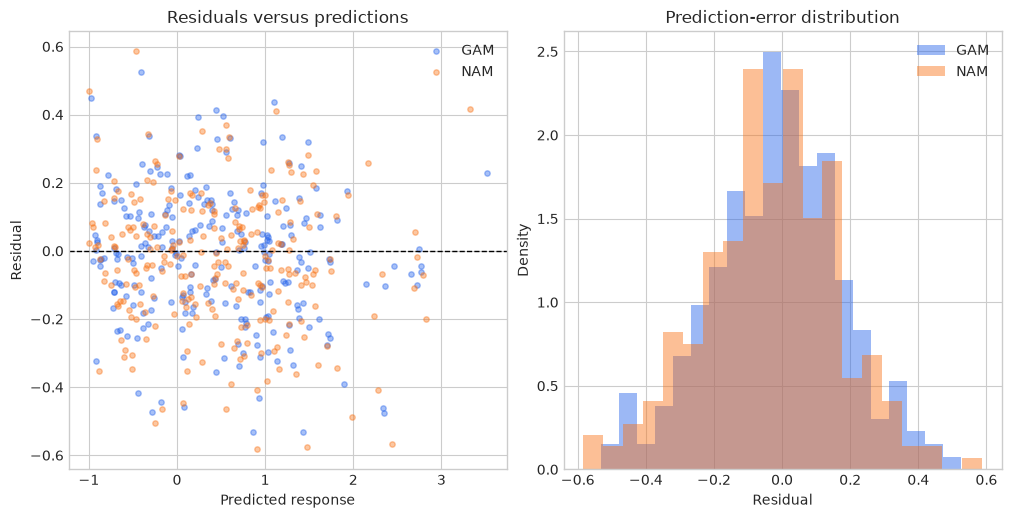

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
for color, (name, fitted) in zip(COLORS, [("GAM", gam), ("NAM", nam)]):
    predicted = fitted.predict(X_test)
    residuals = y_test - predicted
    axes[0].scatter(predicted, residuals, s=15, alpha=0.4, color=color, label=name)
    axes[1].hist(residuals, bins=20, alpha=0.45, density=True, color=color, label=name)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set(xlabel="Predicted response", ylabel="Residual", title="Residuals versus predictions")
axes[1].set(xlabel="Residual", ylabel="Density", title="Prediction-error distribution")
for axis in axes:
    axis.set_box_aspect(1)
    axis.legend()
plt.show()
plt.close(figure)


## Inspect the feature effects

predict_components separates the intercept from the fitted contributions. For these regressors, adding them gives the predicted response.

The level of an individual curve is arbitrary: a constant can be moved from the curve to the intercept without changing a prediction. We center each effect over the training rows so that zero represents its average contribution there.


In [6]:
for fitted_model in (gam, nam):
    components = fitted_model.predict_components(X_test)
    components.validate_additive_reconstruction(rtol=1e-5, atol=1e-6)


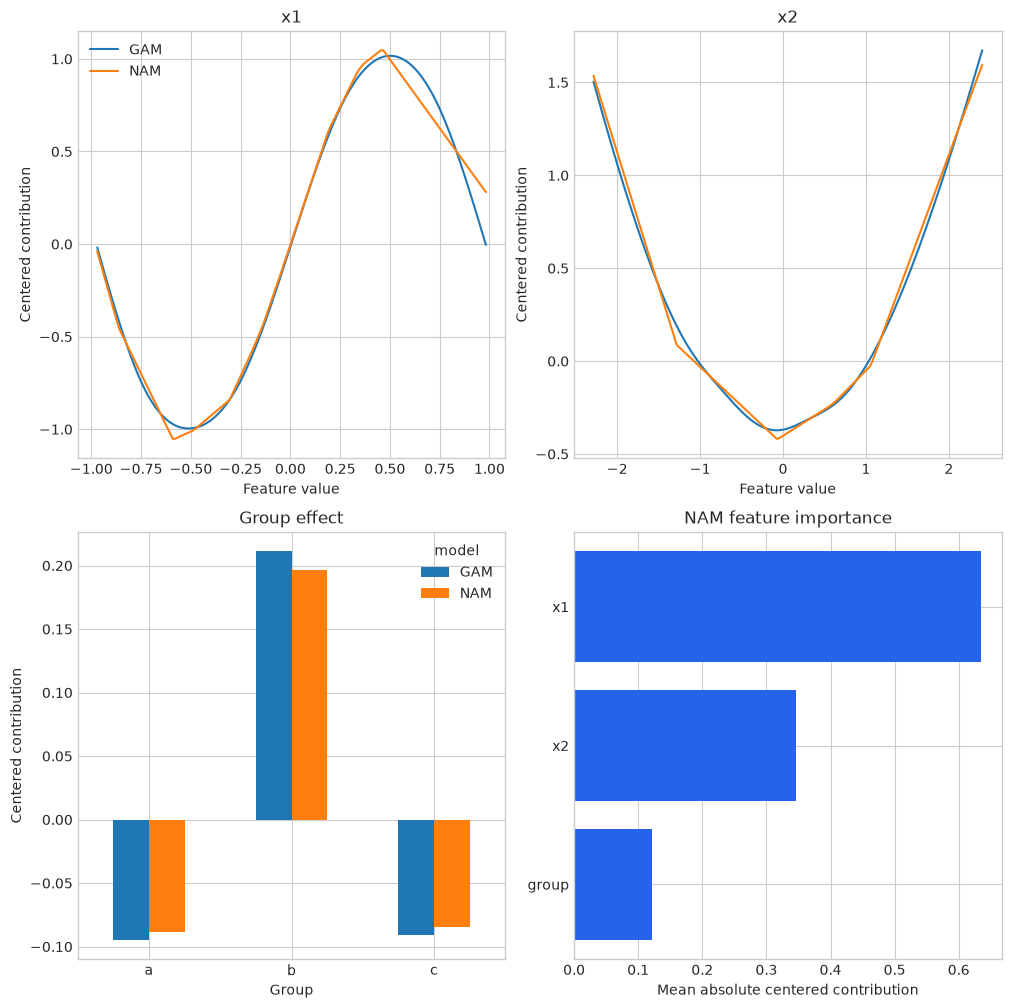

In [7]:
figure, axes = plt.subplots(2, 2, figsize=(10, 10), constrained_layout=True)
axes = axes.ravel()
for name, fitted in [("GAM", gam), ("NAM", nam)]:
    effects = fitted.predict_components(X_train)
    for axis, feature in zip(axes[:2], ["x1", "x2"]):
        values = np.linspace(X_train[feature].quantile(0.01), X_train[feature].quantile(0.99), 160)
        grid = pd.DataFrame({"x1": np.full(160, X_train.x1.median()),
                             "x2": np.full(160, X_train.x2.median()),
                             "group": pd.Categorical(["a"] * 160, categories=X["group"].cat.categories)})
        grid[feature] = values
        key = next(key for key in effects.terms if feature in key)
        contribution = np.asarray(fitted.predict_components(grid).terms[key]).reshape(-1)
        contribution -= np.asarray(effects.terms[key]).mean()
        axis.plot(values, contribution, label=name)
        axis.set(title=feature, xlabel="Feature value", ylabel="Centered contribution")
# Use source-feature grouping for encoded categorical terms.
category_rows = []
for name, fitted in [("GAM", gam), ("NAM", nam)]:
    parts = fitted.predict_components(X_train)
    category_effect = sum(np.asarray(value).reshape(-1) for key, value in parts.terms.items() if "group" in key)
    category_effect -= category_effect.mean()
    for group in X["group"].cat.categories:
        category_rows.append({"model": name, "group": group,
                              "effect": category_effect[X_train["group"] == group].mean()})
pd.DataFrame(category_rows).pivot(index="group", columns="model", values="effect").plot.bar(ax=axes[2], rot=0)
axes[2].set(title="Group effect", xlabel="Group", ylabel="Centered contribution")
axes[0].legend()

importance = nam.term_importance(X_test, center=True, reference_X=X_train).sort_values("importance")
axis = axes[3]
axis.barh(importance["term"], importance["importance"], color=COLORS[0])
axis.set(title="NAM feature importance", xlabel="Mean absolute centered contribution")
for plot_axis in figure.axes:
    plot_axis.set_box_aspect(1)
plt.show()
plt.close(figure)


Positive values raise the prediction relative to the training-data reference; negative values lower it. The numerical panels show how contributions change with x1 and x2. The categorical panel compares the group shifts.

Importance is the average absolute centered contribution on the rows being summarized. It measures the size of an effect in the fitted model, not a causal influence. Correlated features can share the same predictive signal.


## Classification and the link function

For a binary response, a logistic model adds contributions in log-odds. The inverse-logit function turns their sum into a probability. Transform the total predictor, rather than transforming each feature effect and adding the resulting probabilities.

$$p_i=\frac{1}{1+\exp(-\eta_i)}.$$


In [8]:
from nampy.models import GAMClassifier

binary_train = X.iloc[train_index].assign(y=y_binary[train_index])
classifier = GAMClassifier(
    formula="y ~ s(x1, bs='cr', k=8) + s(x2, bs='cr', k=8) + group"
).fit(binary_train, binary_train["y"])

logistic_components = classifier.predict_components(X_test)
logistic_components.validate_additive_reconstruction()


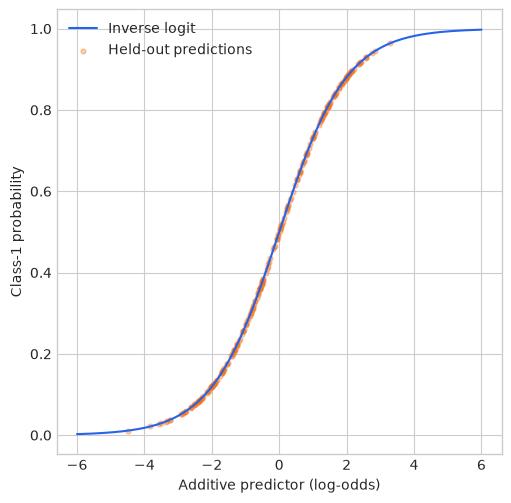

In [9]:
figure, axis = plt.subplots(figsize=(5, 5), constrained_layout=True)
eta = np.linspace(-6, 6, 200)
axis.plot(eta, 1 / (1 + np.exp(-eta)), color=COLORS[0], label="Inverse logit")
axis.scatter(np.asarray(logistic_components.link).reshape(-1),
             np.asarray(logistic_components.response).reshape(-1),
             s=12, alpha=0.35, color=COLORS[1], label="Held-out predictions")
axis.set(xlabel="Additive predictor (log-odds)", ylabel="Class-1 probability")
axis.legend()
for plot_axis in figure.axes:
    plot_axis.set_box_aspect(1)
plt.show()
plt.close(figure)


An equal change in log-odds has its largest effect on probability near 0.5 and a smaller effect near 0 or 1.


The regression examples add contributions directly to the predicted response. In logistic classification, contributions add to log-odds, and the inverse-logit function converts the total to a probability.

The [classification tutorial](05_real_data_classification.ipynb) applies this workflow to data with missing values and categorical features.